# 03 · Prepare retrieval models and PostgreSQL
Download missing model assets, verify existing files, and create compatible storage without generating embeddings.

## Portable project folder and database settings
Keep notebooks 01–05 together in the project folder. All data, models and results use paths relative to that folder through `pathlib`, on macOS, Windows or Linux. The code searches the kernel working directory and its parents for notebook 01. Jupyter does not reliably expose the open notebook's file path; if its working directory is elsewhere, set `RAG_PROJECT_DIR` to the project folder before running configuration. A relative override is resolved from the kernel working directory.

Optional override in a cell before configuration:
```python
import os
os.environ['RAG_PROJECT_DIR'] = 'path/to/your/project'  # Relative, or your native absolute path.
```

Database settings in 03–05 follow this precedence: `RAG_PG_DSN` / `RAG_PG_SCHEMA` environment overrides, then `data/rag_setup_connection.json` saved by 03, then the local defaults. On a new machine, run 03 to prepare the connection before 04/05. Supply the PostgreSQL role in the DSN when it differs from your operating-system username. Credentials remain in your environment or PostgreSQL password file; do not put passwords in notebook cells. A saved endpoint is machine-specific: override it when moving to another server. Notebook 03 saves the effective endpoint without its password.

The scope is intentional: notebook 01 downloads **all 41 English shards**, and notebook 04 embeds only **00000–00007** to limit computation. No download or embedding scope is changed by the portable paths.


## Run order and scope
Run **01 → 02 → 03 → 04 → 05_offline_wikipedia_hybrid_rag.ipynb** from the project directory.
Notebook 01 downloads English Wikipedia; notebook 02 downloads the answer generator. These two new notebooks prepare retrieval storage and embeddings.

“Shards 1–8” means the **first eight files, numbered 00000–00007**, not upstream files 00001–00008. These contain 1,250,310 articles in the pinned snapshot. The full English snapshot is approximately 11.63 GB of compressed Parquet across 41 files; this subset uses about 2.48 GB of source files. Database tables, model weights and indexes require additional disk space.

Use Python 3.11 or 3.12 in a dedicated environment. Existing PostgreSQL must have the pgvector extension installed on the server and a role allowed to create the database/schema/extension. Alternatively, install and start Docker Desktop/Engine and enable the optional container switch in notebook 03. Docker itself is an operating-system prerequisite. No service is restarted or upgraded by these notebooks.

First downloads require internet; model inference and retrieval are local after preparation. A populated database and a corpus-specific BM25 index are **built or restored**, not downloadable pretrained models. This is a reproducible local project pipeline; production deployments also need access control, backups, monitoring and workload-specific evaluation.

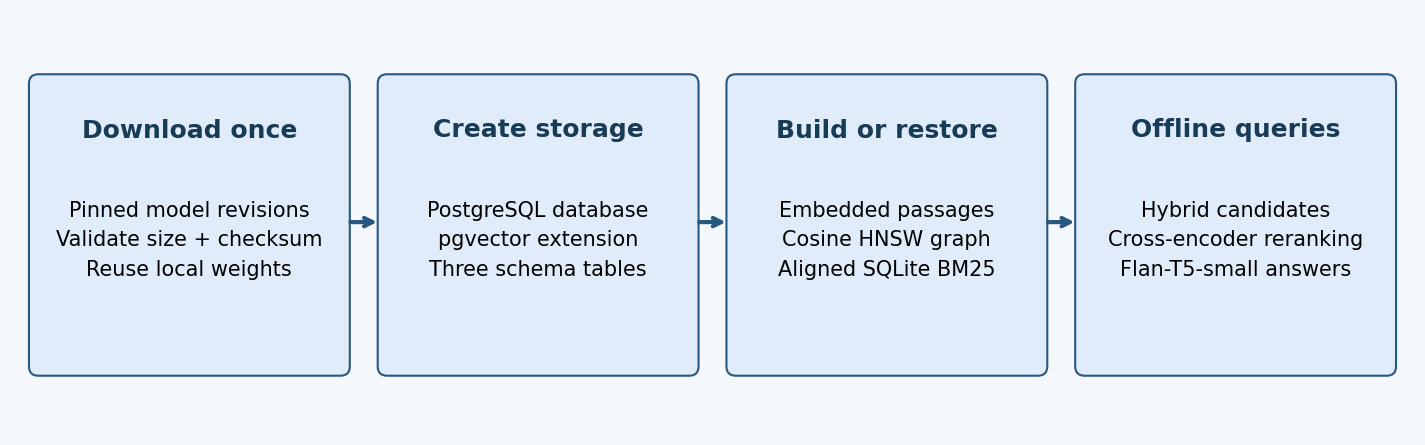

In [1]:
# Install missing packages only, in this notebook kernel. Internet required on first setup.
import importlib.util, subprocess, sys
packages = {'pyarrow':'pyarrow>=14', 'numpy':'numpy', 'psycopg':'psycopg[binary]>=3.2',
            'pgvector':'pgvector>=0.3', 'huggingface_hub':'huggingface-hub',
            'sentence_transformers':'sentence-transformers>=3', 'torch':'torch',
            'transformers':'transformers', 'sentencepiece':'sentencepiece'}
missing=[package for module,package in packages.items() if importlib.util.find_spec(module) is None]
if missing: subprocess.check_call([sys.executable,'-m','pip','install',*missing])
print('Dependencies present. If pip changed an already loaded dependency, restart the kernel.')

Dependencies present. If pip changed an already loaded dependency, restart the kernel.


In [2]:
from pathlib import Path
import os, json
# Paths are relative to the project folder, using native macOS/Windows separators.
def resolve_project_root():
    override = os.environ.get('RAG_PROJECT_DIR')
    if override:
        folder = Path(override).expanduser().resolve()
        if not folder.is_dir():
            raise FileNotFoundError('RAG_PROJECT_DIR must point to an existing project folder.')
        return folder
    current = Path.cwd().resolve()
    for folder in (current, *current.parents):
        if (folder/'01_download_english_wikipedia_dataset.ipynb').is_file():
            return folder
    raise RuntimeError('Open Jupyter from the folder containing notebooks 01–05, or set RAG_PROJECT_DIR to that folder.')

ROOT = resolve_project_root()
ROOT.joinpath('data').mkdir(parents=True, exist_ok=True)
connection_file = ROOT/'data/rag_setup_connection.json'
saved = json.loads(connection_file.read_text(encoding='utf-8')) if connection_file.exists() else {}
DSN = os.environ.get('RAG_PG_DSN') or saved.get('dsn') or 'host=localhost dbname=rag_vectors'
SCHEMA = os.environ.get('RAG_PG_SCHEMA') or saved.get('schema') or 'rag_wiki_bge_full_v1'
print('Project folder:', ROOT)  # Credentials are never printed.


Project folder: /Users/amolsingh/Documents/code/IITB-DL


## Models: different jobs
[BGE-small-en-v1.5](https://huggingface.co/BAAI/bge-small-en-v1.5) turns passages and queries into 384-dimensional vectors for semantic retrieval. This project normalizes embeddings, adds the BGE query instruction only to questions, and preserves its existing 256-token input limit.

[MS MARCO MiniLM-L6-v2](https://huggingface.co/cross-encoder/ms-marco-MiniLM-L6-v2) scores each question–candidate pair after retrieval. It does not create the stored passage vectors. Flan-T5-small, prepared in notebook 02, reads the selected evidence to generate an answer.

Both retrieval models are pinned to the revisions used by the existing collection. Required files are checked by byte size and SHA-256 (large files) or Git blob SHA-1 (small files). Valid local files cause no network call. Missing files download; corrupt files are fetched again. A fresh subprocess avoids inherited Hugging Face offline settings blocking an intentional download.

In [3]:
MODEL_SPECS = [{'repo_id': 'BAAI/bge-small-en-v1.5', 'repo_type': 'model', 'revision': '5c38ec7c405ec4b44b94cc5a9bb96e735b38267a', 'folder': 'bge-small-en-v1.5', 'files': [{'path': '1_Pooling/config.json', 'size': 190, 'git_sha1': '1da070f0993788c8851a652170ff013aa54dd519'}, {'path': 'README.md', 'size': 94783, 'git_sha1': '8b8567d75ffa619486d9590cb0eb76d66ad46c49'}, {'path': 'config.json', 'size': 743, 'git_sha1': '3992bf890728a92476c700e6e657fd696eb94160'}, {'path': 'config_sentence_transformers.json', 'size': 124, 'git_sha1': 'dcb0c0d97d09b930d13600b1a773ddb27e441aab'}, {'path': 'model.safetensors', 'size': 133466304, 'sha256': '3c9f31665447c8911517620762200d2245a2518d6e7208acc78cd9db317e21ad'}, {'path': 'modules.json', 'size': 349, 'git_sha1': '952a9b81c0bfd99800fabf352f69c7ccd46c5e43'}, {'path': 'sentence_bert_config.json', 'size': 52, 'git_sha1': 'ea85692bff64b0d1917833c31ddbca8ab10f5455'}, {'path': 'special_tokens_map.json', 'size': 125, 'git_sha1': 'a8b3208c2884c4efb86e49300fdd3dc877220cdf'}, {'path': 'tokenizer.json', 'size': 711396, 'git_sha1': '688882a79f44442ddc1f60d70334a7ff5df0fb47'}, {'path': 'tokenizer_config.json', 'size': 366, 'git_sha1': '37fca74771bc76a8e01178ce3a6055a0995f8093'}, {'path': 'vocab.txt', 'size': 231508, 'git_sha1': 'fb140275c155a9c7c5a3b3e0e77a9e839594a938'}]}, {'repo_id': 'cross-encoder/ms-marco-MiniLM-L6-v2', 'repo_type': 'model', 'revision': '233902d25c440f23af6f7d6e94d2946bac0bee0a', 'folder': 'ms-marco-MiniLM-L6-v2', 'files': [{'path': 'README.md', 'size': 3673, 'git_sha1': '4c0467b102d751d799638ad2bc0cdf6de56e9745'}, {'path': 'config.json', 'size': 794, 'git_sha1': '88bc4f74b33a2073abc9a66cb532b889448ac3ed'}, {'path': 'model.safetensors', 'size': 90870598, 'sha256': '821d1aa69520101d6e0737f78a042ae25b19e5cb9160701909d10434f4aeb0ae'}, {'path': 'special_tokens_map.json', 'size': 132, 'git_sha1': '7520992f25914d962f0e2fd0e0566fc33d19ec59'}, {'path': 'tokenizer.json', 'size': 711396, 'git_sha1': '688882a79f44442ddc1f60d70334a7ff5df0fb47'}, {'path': 'tokenizer_config.json', 'size': 1330, 'git_sha1': 'a2435fedfac32b9ad70f052d4f84007730cd3109'}, {'path': 'vocab.txt', 'size': 231508, 'git_sha1': 'fb140275c155a9c7c5a3b3e0e77a9e839594a938'}]}]

In [4]:
# Shared setup definitions embedded in the preparation notebooks.
from pathlib import Path
from contextlib import contextmanager
import os,sys,json,re,time,hashlib,shutil,subprocess,importlib.util,threading,socket,getpass
import pyarrow.parquet as pq  # Import before torch to avoid conflicting OpenMP initialization.
import numpy as np
import psycopg
from psycopg import sql
from psycopg.rows import dict_row
from psycopg.conninfo import conninfo_to_dict,make_conninfo
from pgvector.psycopg import register_vector
from pgvector import HalfVector

def safe_schema(name):
    if not re.fullmatch(r'rag_[a-z0-9_]{1,50}',name):raise ValueError('Use a schema beginning rag_ with lowercase letters/digits/underscores.')
    return name

def connect(dsn,vector=True):
    db=psycopg.connect(dsn,autocommit=True,row_factory=dict_row,connect_timeout=5)
    if vector:register_vector(db)
    return db

@contextmanager
def writer_lock(db,schema):
    locked=db.execute('SELECT pg_try_advisory_lock(hashtext(%s)) AS ok',(schema,)).fetchone()['ok']
    if not locked:raise RuntimeError('Another ingestion/index writer is active for this schema; retry after it finishes.')
    try:yield
    finally:db.execute('SELECT pg_advisory_unlock(hashtext(%s))',(schema,))

def get_meta(db,schema):
    return {r['key']:r['value'] for r in db.execute(f'SELECT * FROM {safe_schema(schema)}.metadata')}

def put_meta(db,schema,key,value):
    db.execute(f'INSERT INTO {safe_schema(schema)}.metadata VALUES (%s,%s::jsonb) ON CONFLICT(key) DO UPDATE SET value=excluded.value',(key,json.dumps(value)))

def file_hash(path,algorithm='sha256',git_header=False):
    digest=hashlib.new(algorithm)
    if git_header:digest.update(f'blob {path.stat().st_size}\0'.encode())
    with path.open('rb') as stream:
        for block in iter(lambda:stream.read(8*1024*1024),b''):digest.update(block)
    return digest.hexdigest()

def asset_valid(path,entry,verify=True):
    if not path.is_file() or path.stat().st_size!=entry['size']:return False
    if not verify:return True
    return file_hash(path) == entry['sha256'] if 'sha256' in entry else file_hash(path,'sha1',True)==entry['git_sha1']

def ensure_models(root,specs,allow_download=True,verify=True):
    for spec in specs:
        folder=Path(root)/'models'/spec['folder']
        invalid=[e for e in spec['files'] if not asset_valid(folder/e['path'],e,verify)]
        if not invalid:print(spec['repo_id'],': verified; download skipped.');continue
        if not allow_download:raise FileNotFoundError(f"Missing/invalid model files: {spec['repo_id']}")
        folder.mkdir(parents=True,exist_ok=True)
        if shutil.disk_usage(folder).free<sum(e['size'] for e in invalid)+256*1024**2:raise OSError('Insufficient free space for model download.')
        # Fresh subprocess ignores offline flags inherited from an earlier RAG session.
        payload=dict(repo_id=spec['repo_id'],revision=spec['revision'],local_dir=str(folder.resolve()),
                     missing=[e['path'] for e in invalid if not (folder/e['path']).exists()],
                     repair=[e['path'] for e in invalid if (folder/e['path']).exists()])
        program="""import json,sys
from huggingface_hub import snapshot_download
p=json.load(sys.stdin)
for key,force in [('missing',False),('repair',True)]:
 if p[key]:snapshot_download(p['repo_id'],revision=p['revision'],local_dir=p['local_dir'],allow_patterns=p[key],force_download=force,max_workers=4)
"""
        env=os.environ.copy()
        for key in ['HF_HUB_OFFLINE','TRANSFORMERS_OFFLINE','HF_DATASETS_OFFLINE']:env[key]='0'
        subprocess.run([sys.executable,'-u','-c',program],input=json.dumps(payload),text=True,env=env,check=True)
        if any(not asset_valid(folder/e['path'],e,verify) for e in spec['files']):raise RuntimeError('Model download did not validate; rerun to resume.')
        print(spec['repo_id'],': download complete.')

DDL_TEMPLATE='''CREATE SCHEMA IF NOT EXISTS {schema};
CREATE TABLE IF NOT EXISTS {schema}.metadata (
    key text PRIMARY KEY, value jsonb NOT NULL
);
CREATE TABLE IF NOT EXISTS {schema}.chunks (
    id bigint GENERATED ALWAYS AS IDENTITY PRIMARY KEY,
    chunk_id text UNIQUE NOT NULL,
    article_id text NOT NULL, title text NOT NULL, url text NOT NULL,
    body text NOT NULL, char_start integer NOT NULL, char_end integer NOT NULL,
    embedding halfvec(384) NOT NULL
);
CREATE TABLE IF NOT EXISTS {schema}.checkpoints (
    unit text PRIMARY KEY, articles bigint, chunks bigint, seconds double precision
);'''

def provision_database(dsn,*,use_docker=False,docker_name='wiki-rag-postgres',docker_image='pgvector/pgvector:pg16'):
    params=conninfo_to_dict(dsn);target=params.get('dbname','rag_vectors');db=None
    try:db=connect(dsn,vector=False)
    except psycopg.errors.InvalidCatalogName:
        admin=connect(make_conninfo(dsn,dbname='postgres'),vector=False)
        try:
            if not admin.execute('SELECT 1 FROM pg_database WHERE datname=%s',(target,)).fetchone():
                admin.execute(sql.SQL('CREATE DATABASE {}').format(sql.Identifier(target)))
        finally:admin.close()
        db=connect(dsn,vector=False)
    except psycopg.OperationalError:
        host=params.get('host','localhost');port=int(params.get('port',5432))
        if not use_docker or host not in {'localhost','127.0.0.1'}:raise
        # Never launch a competing server when the target port already has a service.
        try:
            sock=socket.create_connection((host,port),timeout=2);sock.close();occupied=True
        except OSError:occupied=False
        if occupied:raise RuntimeError('PostgreSQL port is occupied but login failed. Fix credentials; no second server was started.')
        if not shutil.which('docker'):raise RuntimeError('Install and start Docker Desktop/Engine, or configure an existing PostgreSQL server with pgvector; then rerun.')
        subprocess.run(['docker','info'],check=True,stdout=subprocess.DEVNULL)
        if not re.fullmatch(r'[a-zA-Z0-9_-]+',docker_name):raise ValueError('Invalid container name.')
        existing=subprocess.run(['docker','inspect',docker_name],capture_output=True,text=True)
        password=params.get('password') or os.environ.get('PGPASSWORD') or getpass.getpass('PostgreSQL password for the local RAG container: ')
        if not password:raise ValueError('A non-empty PostgreSQL password is required.')
        if existing.returncode==0:
            info=json.loads(existing.stdout)[0]
            if info.get('Config',{}).get('Labels',{}).get('rag.setup')!='wikipedia-eight-shards':raise RuntimeError('Container name belongs to another service. Choose a different name.')
            ports=info.get('HostConfig',{}).get('PortBindings',{}).get('5432/tcp',[])
            if not any(p.get('HostPort')==str(port) and p.get('HostIp')=='127.0.0.1' for p in ports):raise RuntimeError('Existing container port does not match the requested endpoint.')
            subprocess.run(['docker','start',docker_name],check=True,stdout=subprocess.DEVNULL)
        else:
            # Password supplied via child environment, never embedded in command arguments/output.
            env=os.environ.copy();env['POSTGRES_PASSWORD']=password
            subprocess.run(['docker','run','-d','--name',docker_name,'--label','rag.setup=wikipedia-eight-shards',
                '--restart','unless-stopped','-p',f'127.0.0.1:{port}:5432','-e','POSTGRES_PASSWORD','-e','POSTGRES_DB='+target,
                '-v',docker_name+'-data:/var/lib/postgresql/data',docker_image],env=env,check=True,stdout=subprocess.DEVNULL)
        os.environ['PGPASSWORD']=password
        dsn=make_conninfo(host='127.0.0.1',port=port,user='postgres',dbname=target)
        for attempt in range(30):
            try:db=connect(dsn,vector=False);break
            except psycopg.OperationalError:time.sleep(2)
        if db is None:raise RuntimeError('Container started but PostgreSQL is not ready; inspect Docker logs and retry.')
    try:
        db.execute('CREATE EXTENSION IF NOT EXISTS vector')
        version=db.execute("SELECT extversion FROM pg_extension WHERE extname='vector'").fetchone()['extversion']
        if tuple(int(x) for x in version.split('.')[:2])<(0,7):raise RuntimeError('halfvec requires pgvector 0.7 or newer; upgrade separately.')
        print('PostgreSQL connected; pgvector',version)
    finally:db.close()
    return dsn

def ensure_tables(db,schema):
    schema=safe_schema(schema)
    with writer_lock(db,schema),db.transaction():
        for statement in DDL_TEMPLATE.format(schema=schema).split(';'):
            if statement.strip():db.execute(statement)
        required={'chunks':{'id':'bigint','chunk_id':'text','article_id':'text','title':'text','url':'text','body':'text','char_start':'integer','char_end':'integer','embedding':'halfvec(384)'},
                  'metadata':{'key':'text','value':'jsonb'},'checkpoints':{'unit':'text','articles':'bigint','chunks':'bigint','seconds':'double precision'}}
        for table,expected in required.items():
            rows=db.execute('SELECT a.attname,format_type(a.atttypid,a.atttypmod) AS type FROM pg_attribute a WHERE a.attrelid=to_regclass(%s) AND a.attnum>0 AND NOT a.attisdropped',(schema+'.'+table,)).fetchall()
            if {r['attname']:r['type'] for r in rows}!=expected:raise RuntimeError('Existing '+table+' table is incompatible; use a separate schema, do not overwrite it.')
        constraints=db.execute("SELECT pg_get_constraintdef(oid) AS definition FROM pg_constraint WHERE conrelid=to_regclass(%s)",(schema+'.chunks',)).fetchall()
        defs={r['definition'] for r in constraints}
        if 'PRIMARY KEY (id)' not in defs or 'UNIQUE (chunk_id)' not in defs:raise RuntimeError('Missing passage identity constraints.')
    print('Schema and tables validated:',schema)

In [5]:
ensure_models(ROOT, MODEL_SPECS, allow_download=True, verify=True)

BAAI/bge-small-en-v1.5 : verified; download skipped.
cross-encoder/ms-marco-MiniLM-L6-v2 : verified; download skipped.


## Database, schema and tables
`rag_vectors` is the database; `rag_wiki_bge_full_v1` is a namespace inside it. The namespace is retained for compatibility with the existing RAG even though only eight shards are populated.

| Table / column | Meaning and reason |
|---|---|
| `chunks.id` | Generated bigint primary key; stable join key used by both retrieval paths. |
| `chunks.chunk_id` | Unique `article_id:start:end`; prevents duplicate passage insertion. |
| `article_id`, `title`, `url` | Wikipedia identity and citation information. |
| `body`, `char_start`, `char_end` | Exact source passage and character offsets for inspection. |
| `embedding` | 384-dimensional `halfvec`; two bytes per coordinate, with some rounding relative to float32. |
| `checkpoints.unit` | Primary key `shard_filename:batch_number`; committed with its passages. |
| `checkpoints.articles/chunks/seconds` | Batch coverage and processing duration. |
| `metadata.key/value` | JSON provenance: model revision, chunk rules, source manifest and readiness audit. |

There is no SQL foreign key between checkpoints and passages: a checkpoint describes a committed batch rather than a passage owner. Atomic transactions and count/coverage checks enforce the resume contract. Checkpoints represent completed batches, not individually guessed article presence. Unknown rows or incompatible provenance cause an error rather than silent reuse.

HNSW is an approximate nearest-neighbor graph on `chunks.embedding`, stored in PostgreSQL alongside the table. Cosine uses `halfvec_cosine_ops`, `m=16`, `ef_construction=128`. A B-tree on `(article_id,char_start)` supports article lead/context lookups. SQLite FTS5 stores the lexical index separately; its `rowid` equals PostgreSQL `chunks.id`. A restored database must preserve those IDs to reuse the same BM25 file.

Reference: [pgvector storage and HNSW documentation](https://github.com/pgvector/pgvector).

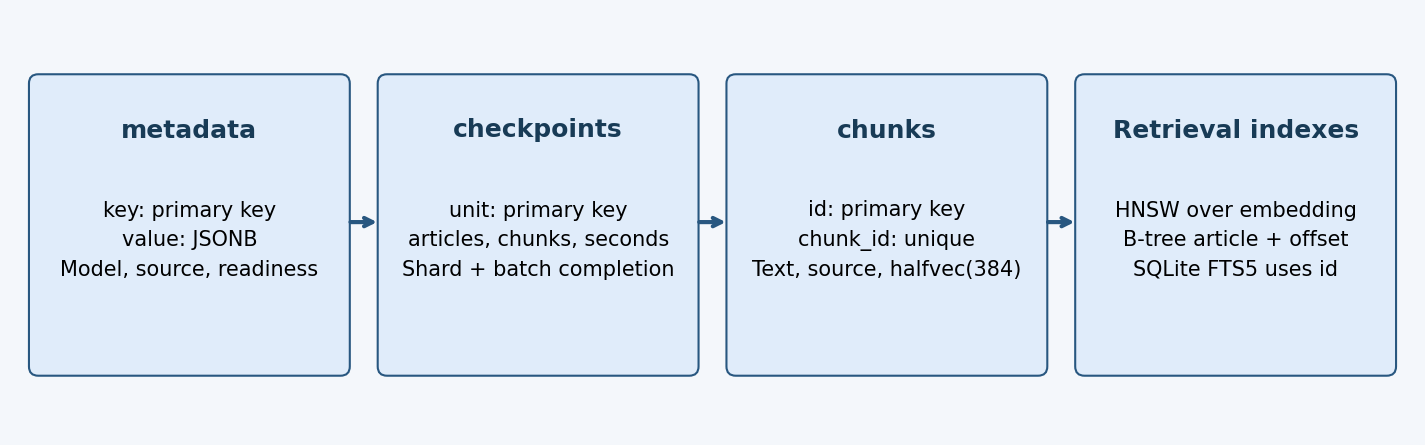

## Actual creation SQL
The next cell displays the SQL used below. Existing compatible tables are preserved; incompatible types or missing passage identity constraints stop setup.

In [6]:
print(DDL_TEMPLATE.format(schema=safe_schema(SCHEMA)))

CREATE SCHEMA IF NOT EXISTS rag_wiki_bge_full_v1;
CREATE TABLE IF NOT EXISTS rag_wiki_bge_full_v1.metadata (
    key text PRIMARY KEY, value jsonb NOT NULL
);
CREATE TABLE IF NOT EXISTS rag_wiki_bge_full_v1.chunks (
    id bigint GENERATED ALWAYS AS IDENTITY PRIMARY KEY,
    chunk_id text UNIQUE NOT NULL,
    article_id text NOT NULL, title text NOT NULL, url text NOT NULL,
    body text NOT NULL, char_start integer NOT NULL, char_end integer NOT NULL,
    embedding halfvec(384) NOT NULL
);
CREATE TABLE IF NOT EXISTS rag_wiki_bge_full_v1.checkpoints (
    unit text PRIMARY KEY, articles bigint, chunks bigint, seconds double precision
);


## Connect or provision
Default: connect to the existing server and create a missing database, extension and tables if the role has permission. Set `USE_DOCKER_IF_SERVER_MISSING=True` only to create a local pgvector container when no server is listening. Docker pulls its image on first use and stores database files in the persistent named volume `wiki-rag-postgres-data`.

Use `RAG_PG_DSN` for a remote server or custom credentials. Prefer `.pgpass` or `PGPASSWORD`; passwords are excluded from the saved connection file. On another kernel/machine, supply those credentials again. A failed login on an occupied port does not start a competing database. This step creates empty tables on a fresh machine; notebook 04 populates them.

In [7]:
USE_DOCKER_IF_SERVER_MISSING = False
DSN = provision_database(DSN, use_docker=USE_DOCKER_IF_SERVER_MISSING)
with connect(DSN) as db:
    ensure_tables(db, SCHEMA)
public = conninfo_to_dict(DSN)
public.pop('password', None)
connection_file.write_text(json.dumps({'dsn': make_conninfo(**public), 'schema':SCHEMA}, indent=2))
print('Storage prepared. Next run notebook 04; no embedding job was started here.')

PostgreSQL connected; pgvector 0.8.7
Schema and tables validated: rag_wiki_bge_full_v1
Storage prepared. Next run notebook 04; no embedding job was started here.


## Moving an existing collection instead of recomputing
Use PostgreSQL `pg_dump`/`pg_restore` for a logical backup containing all three tables and index definitions. Restore into a compatible PostgreSQL/pgvector installation. Logical restore rebuilds HNSW from its definition; it does **not** recompute embeddings. Copy the matching BM25 SQLite file only when no lexical build is active. Also copy model folders or let this notebook download them.

Notebook 04 verifies provenance, checkpoint coverage and lexical alignment before reuse. Never pair a BM25 file with newly assigned PostgreSQL passage IDs. Notebook 05 resolves the same project root and reads the saved connection settings. Set `RAG_PG_DSN`/credentials when using a different endpoint.